# 演習9：06の準備回路だけをjoint-state圧縮へ置き換える

06を基に、**準備Aと逆準備A†を08のjoint準備へ置き換え**ます。
発展回路は同じH₄・R=2.0 Å・M16、transpilerは06と同じlevel 1です。
較正を使う配置探索、level 3、twirling、DDは追加しません。

信号が見えた08の条件に合わせ、既定は **L=1・位相一周期の12点** です。
06のL=4・エネルギー候補9点の実験をそのまま再現するものではありません。
`L=4` に変えると06と同じ発展時間で、joint準備による信号が残るかを確認できます。

| 量 | 設定 |
|---|---|
| 分子・発展 | 06と同じ直鎖H₄/STO-3G/JW、準備標的M6、発展M16 |
| 準備 | 標的は06のjoint-state、8層・32個の局所2-qubit unitaryへ直接圧縮 |
| 時間 | L=1、Δt=0.1、t=0.1 a.u.（L=4へ変更可） |
| 候補 | β∈[-π,π)の12点、ε=β/t |
| 読出し | 全9ビットが0の回数 / 実shots数 |
| shots | 各点1024、1走査12,288 shots |
| fake | FakeKawasakiのゲート・読出しノイズ、06と同じ方式 |

第2・3節のGaussian更新は06から残した参考表示です。位相一周期の広い走査では、これを高精度なギャップ推定とは解釈しません。
fakeと実機は全0countsと位相依存性を診断し、Gaussian更新を強制しません。
既定ではfakeを実行し、IBM接続・実機送信は無効です。


In [1]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"
# 実機モードのみ追加: %pip install "qiskit-ibm-runtime>=0.43,<0.44"


### データの取得先とキャッシュ

巨大な保存配列はNotebookへ埋め込みません。次セルは固定コミットから必要な回路・参照データを取得し、SHA-256を確認して再利用します。
リポジトリを取得済みなら、その中の固定データを優先します。なければローカルの `~/.cache/ftqc_handson/h4_pec_v1` へ保存します。
次セル先頭の `H4_CACHE_DIR` にパスを指定すると保存先を変えられます（環境変数 `H4_DATA_DIR` があればそちらが優先）。

Google Driveへ保存する場合は、先に別セルで次を実行し、その後 `H4_CACHE_DIR` を下記のパスに変更してください。

```python
from google.colab import drive
drive.mount('/content/drive')
# 次の初期化セルで指定:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
```

初回はネット接続が必要です。構造やMを変えたときは不足ファイルだけを取得し、既存ファイルは再ダウンロードしません。
オフラインで全選択肢を使う場合は、接続中に `download_h4_data()` で全20構造を事前取得します（約40 MiB）。
その後は `H4_OFFLINE=True` を選べます。補助コードも保存先の隣のruntimeフォルダへキャッシュします。
初期化セルは補助関数のため折り畳んであります。通常は先頭の設定だけを変更して実行してください。


In [2]:
H4_DATA_COMMIT = "4ab6ef3d06f4256b5c818feb8c3fa2af4381dd43"
# 保存先を指定する場合の例（Google Driveは先にmountする）:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
H4_CACHE_DIR = (
    None  # None: H4_DATA_DIR環境変数 → 取得済みリポジトリ → ユーザーキャッシュ
)
H4_OFFLINE = False  # True: ダウンロードせず、既存ファイルのみを使用

import os, json, hashlib, base64, tempfile
from pathlib import Path
from urllib.request import urlopen

SNAPSHOT_DIGEST = "6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3"
ASSET_DIGEST = SNAPSHOT_DIGEST
_H4_URL = f"https://raw.githubusercontent.com/QS-laboratory/IBM_handson/{H4_DATA_COMMIT}/hands_on/exercises/"
_H4_RUNTIME = {
    "h4_measurement.py": "d4dea4170f5e925599dcbbbc3b2c0ee7f2da1e25d7844ec024759e415c3a35f4",
    "h4_snapshot.py": "163691a0c005c844e0e449411c59eb5192218402df999c77056cbd7b223be997",
}


def snapshot_root():
    explicit = os.environ.get("H4_DATA_DIR") or H4_CACHE_DIR
    root = Path(explicit).expanduser().resolve() if explicit else None
    if root is None:
        for parent in [Path.cwd(), *Path.cwd().parents]:
            for candidate in [
                parent / "data/h4_pec_v1",
                parent / "hands_on/exercises/data/h4_pec_v1",
            ]:
                if (candidate / "manifest.json").is_file():
                    root = candidate
                    break
            if root is not None:
                break
    if root is None:
        root = Path.home() / ".cache/ftqc_handson/h4_pec_v1"
    if (
        str(root).startswith("/content/drive/MyDrive/")
        and not Path("/content/drive/MyDrive").is_dir()
    ):
        raise FileNotFoundError(
            '先に drive.mount("/content/drive") でGoogle Driveを接続してください'
        )
    manifest = root / "manifest.json"
    if (
        manifest.is_file()
        and hashlib.sha256(manifest.read_bytes()).hexdigest() != SNAPSHOT_DIGEST
    ):
        raise ValueError("Snapshot manifest differs from the pinned h4-pec-v1 manifest")
    return root


def _h4_fetch(path, url, digest):
    path = Path(path)
    if path.is_file():
        raw = path.read_bytes()
    else:
        if H4_OFFLINE:
            raise FileNotFoundError(
                f"Offline: missing {path}; pre-download the required data"
            )
        try:
            with urlopen(url, timeout=60) as response:
                raw = response.read()
        except Exception as exc:
            raise RuntimeError(
                f"H4データを取得できません: {path.name}. 接続またはH4_DATA_DIR/H4_CACHE_DIRを確認してください。"
            ) from exc
        if hashlib.sha256(raw).hexdigest() != digest:
            raise ValueError(f"Snapshot checksum mismatch: {path.name}")
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = None
        try:
            with tempfile.NamedTemporaryFile(dir=path.parent, delete=False) as stream:
                tmp = Path(stream.name)
                stream.write(raw)
            os.replace(tmp, path)
        finally:
            if tmp is not None:
                tmp.unlink(missing_ok=True)
    if hashlib.sha256(raw).hexdigest() != digest:
        raise ValueError(f"Snapshot checksum mismatch: {path.name}")
    return raw


def _h4_data(relative):
    digest = (
        SNAPSHOT_DIGEST
        if relative == "manifest.json"
        else SNAPSHOT_INDEX["files"][relative]
    )
    return _h4_fetch(
        snapshot_root() / relative, _H4_URL + "data/h4_pec_v1/" + relative, digest
    )


SNAPSHOT_INDEX = json.loads(_h4_data("manifest.json"))


class _H4Assets:
    """Read only the requested asset; no notebook-embedded binary strings."""

    def __init__(self, row):
        self.row = row

    def __getitem__(self, key):
        raw = _h4_data(self.row["id"] + "/" + self.row["assets"][key])
        return base64.b64encode(raw).decode()


def _h4_geometry(geometry):
    row = next((r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None)
    if row is None:
        raise ValueError("Unknown GEOMETRY; choose an ID from list_geometries()")
    cat = json.loads(_h4_data(geometry + "/catalog.json"))
    for name in ["preparation", "evolution"]:
        cat[name] = {int(k) if k != "exact" else k: v for k, v in cat[name].items()}
    return _H4Assets(row), cat, json.loads(_h4_data(geometry + "/provenance.json"))


ASSETS, CIRCUIT_CATALOG, PROVENANCE = _h4_geometry("R_2p00000000")
exec(
    compile(_h4_data("exact_preparation.py"), "h4_pec_v1/exact_preparation.py", "exec"),
    globals(),
)
_h4_cache_root = snapshot_root
for _name, _digest in _H4_RUNTIME.items():
    _local = snapshot_root().parent.parent / "tools" / _name
    _path = (
        _local
        if _local.is_file()
        else snapshot_root().parent
        / (snapshot_root().name + "_runtime")
        / H4_DATA_COMMIT
        / _name
    )
    exec(
        compile(_h4_fetch(_path, _H4_URL + "tools/" + _name, _digest), _name, "exec"),
        globals(),
    )
# The pinned runtime supplies measurement/inference helpers. Replace its eager
# snapshot reader with the verified, per-file cache above.
snapshot_geometry = _h4_geometry
snapshot_root = _h4_cache_root


def download_h4_data(
    geometries="all", prep_m=(4, 6, 8, "exact"), evolution_m=(8, 16, 32, "exact")
):
    """Optional prefetch for offline use. This never changes active circuits."""
    ids = (
        [r["id"] for r in SNAPSHOT_INDEX["geometries"]]
        if geometries == "all"
        else list(geometries)
    )
    count = 0
    for geometry in ids:
        row = next(
            (r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None
        )
        if row is None:
            raise ValueError("Unknown GEOMETRY")
        assets, cat, _ = _h4_geometry(geometry)
        keys = {"model"}
        for m in prep_m:
            keys.update(cat["preparation"][m]["keys"].values())
        for m in evolution_m:
            keys.add(cat["evolution"][m]["key"])
        for key in sorted(keys):
            assets[key]
            count += 1
    print(f"Cached {len(ids)} geometries / {count} assets in {snapshot_root()}")


print(
    "H4 data cache:",
    snapshot_root(),
    "— missing files are downloaded on demand; existing files are verified and reused.",
)

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
H4 data cache: /Users/payashi/Documents/research/IBM_handson/hands_on/exercises/data/h4_pec_v1 — missing files are downloaded on demand; existing files are verified and reused.


## 0．固定回路・joint準備・shots数

下の設定で `SHOTS` と `L` を選びます。最初はL=1、1024 shotsを使ってください。
準備標的は06と同じ実際の近似joint-stateです。08と同じSVD sweepで直接圧縮し、
fidelityが0.99以上であることを確認してからAを置き換えます。再実行すると元のM6を読み直して圧縮します。
最適化の実装は9-qubitのdense状態を用いる小規模版です。大規模MPS縮約の実装ではありません。


### joint圧縮と信号診断の補助関数

08のjoint圧縮だけを再利用します。配置探索・DD・twirlingの関数は読み込みません。


In [3]:
CHAIN = (8, 0, 1, 2, 3, 4, 5, 6, 7)

def joint_mps(target, chi=16):
    """TT-SVD of the nine-qubit joint state in ancilla-first chain order."""
    target = np.asarray(target, complex)
    if target.shape != (512,) or not np.isclose(np.linalg.norm(target), 1):
        raise ValueError("A normalized nine-qubit joint target is required")
    if not isinstance(chi, int) or isinstance(chi, bool) or chi < 1:
        raise ValueError("chi must be a positive integer")
    axes = [8-q for q in CHAIN]
    tensor = target.reshape([2]*9).transpose(axes)
    cores, rank = [], 1
    for _ in range(8):
        u, s, vh = np.linalg.svd(tensor.reshape(rank*2, -1), full_matrices=False)
        keep = min(chi, len(s))
        cores.append(u[:, :keep].reshape(rank, 2, keep))
        tensor = s[:keep, None]*vh[:keep]
        rank = keep
    cores.append(tensor.reshape(rank, 2, 1))
    rebuilt = cores[0][0]
    for core in cores[1:]:
        rebuilt = np.tensordot(rebuilt, core, axes=(-1, 0))
    state = rebuilt[..., 0].transpose(np.argsort(axes)).reshape(-1)
    retained = float(np.linalg.norm(state)**2)
    state /= np.sqrt(retained)
    return cores, state, retained

def two_site_view(state, pair):
    # Qiskit's two-qubit matrix basis is |q_second q_first>.
    a, b = pair
    axes = [8-b, 8-a]+[i for i in range(9) if i not in (8-b, 8-a)]
    return state.reshape([2]*9).transpose(axes).reshape(4, -1), axes

def apply_two(state, gate, pair):
    matrix, axes = two_site_view(state, pair)
    return (gate@matrix).reshape([2]*9).transpose(np.argsort(axes)).reshape(-1)

def initial_joint_state():
    # A product determinant times |+>_ancilla, prepared without controlled gates.
    state = np.zeros(512, complex)
    state[165] = state[165+256] = 1/np.sqrt(2)
    return state

def compress_joint(target, layers=8, sweeps=2000, seeds=(3, 17, 42), chi=16):
    if layers < 1 or sweeps < 1 or not seeds:
        raise ValueError("Positive layers/sweeps and at least one seed are required")
    cores, mps_target, retained = joint_mps(target, chi)
    pairs = [(CHAIN[j], CHAIN[j+1]) for layer in range(layers)
             for j in range(layer % 2, 8, 2)]
    best, runs = None, []
    for seed in seeds:
        rng = np.random.default_rng(seed)
        gates = []
        for _ in pairs:
            z = np.eye(4)+.05*(rng.normal(size=(4, 4))+1j*rng.normal(size=(4, 4)))
            u, _, vh = np.linalg.svd(z)
            gates.append(u@vh)
        history = []
        for sweep in range(sweeps):
            if sweep % 2 == 0:
                suffix = [None]*(len(gates)+1)
                suffix[-1] = mps_target
                for j in reversed(range(len(gates))):
                    suffix[j] = apply_two(suffix[j+1], gates[j].conj().T, pairs[j])
                state = initial_joint_state()
                for j, pair in enumerate(pairs):
                    x, _ = two_site_view(state, pair)
                    y, _ = two_site_view(suffix[j+1], pair)
                    u, _, vh = np.linalg.svd(y@x.conj().T)
                    gates[j] = u@vh
                    state = apply_two(state, gates[j], pair)
            else:
                prefix = [initial_joint_state()]
                for gate, pair in zip(gates, pairs):
                    prefix.append(apply_two(prefix[-1], gate, pair))
                state = mps_target.copy()
                for j in reversed(range(len(gates))):
                    x, _ = two_site_view(prefix[j], pairs[j])
                    y, _ = two_site_view(state, pairs[j])
                    u, _, vh = np.linalg.svd(y@x.conj().T)
                    gates[j] = u@vh
                    state = apply_two(state, gates[j].conj().T, pairs[j])
            prepared = initial_joint_state()
            for gate, pair in zip(gates, pairs):
                prepared = apply_two(prepared, gate, pair)
            history.append(float(abs(np.vdot(mps_target, prepared))**2))
        fidelity = float(abs(np.vdot(target, prepared))**2)
        runs.append(dict(seed=seed, fidelity=fidelity, history=history))
        print(f"Joint compression: seed={seed}, fidelity={fidelity:.8f}", flush=True)
        if best is None or fidelity > best["fidelity"]:
            best = dict(fidelity=fidelity, gates=np.array(gates), seed=seed)
    circuit = QuantumCircuit(9, name="joint_MPS_compressed")
    for q in (0, 2, 5, 7):
        circuit.x(q)
    circuit.h(8)
    for gate, pair in zip(best["gates"], pairs):
        circuit.unitary(gate, list(pair))
    actual = Statevector.from_instruction(circuit).data
    np.testing.assert_allclose(abs(np.vdot(target, actual))**2, best["fidelity"], atol=1e-11)
    fingerprint = hashlib.sha256(best["gates"].tobytes()+np.array(pairs).tobytes()).hexdigest()
    report = dict(layers=layers, sweeps=sweeps, seeds=list(seeds), selected_seed=best["seed"],
                  chi=chi, bond_dimensions=[c.shape[2] for c in cores[:-1]],
                  mps_retained_norm_squared=retained, fidelity=best["fidelity"],
                  circuit_digest=fingerprint, two_qubit_blocks=len(pairs), runs=runs)
    return circuit, report

def wilson_interval(k, n, z=1.959963984540054):
    k, n = np.asarray(k, float), np.asarray(n, float)
    if np.any(n <= 0) or np.any(k < 0) or np.any(k > n):
        raise ValueError("0 <= counts <= positive shots が必要です")
    p = k / n
    denominator = 1 + z * z / n
    center = (p + z * z / (2 * n)) / denominator
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return np.maximum(0, center - half), np.minimum(1, center + half)

def summarize_scan(beta, k, n, seed=42, simulations=4999):
    beta = np.asarray(beta, float)
    k, n = np.asarray(k), np.asarray(n)
    if (
        beta.ndim != 1
        or len(beta) < 3
        or k.shape != beta.shape
        or n.shape != beta.shape
        or not np.all(np.isfinite(beta))
        or not np.issubdtype(k.dtype, np.integer)
        or not np.issubdtype(n.dtype, np.integer)
        or np.any(n <= 0)
        or np.any(k < 0)
        or np.any(k > n)
    ):
        raise ValueError("位相と整数counts/shotsの配列を確認してください")
    basis = np.column_stack([np.cos(beta), np.sin(beta)])
    design = np.column_stack([np.ones(len(beta)), basis])
    if np.linalg.matrix_rank(design) != 3:
        raise ValueError("位相点が干渉曲線を決定できません")
    coefficients = np.linalg.lstsq(
        design * np.sqrt(n[:, None]), k / np.sqrt(n), rcond=None
    )[0]
    low, high = wilson_interval(k, n)
    total, trials = int(k.sum()), int(n.sum())
    pooled = total / trials
    centered = basis - np.average(basis, axis=0, weights=n)
    metric = np.linalg.pinv(centered.T @ (n[:, None] * centered))
    score = (k - n * pooled) @ centered
    statistic = float(score @ metric @ score)
    if total == 0 or total == trials:
        pvalue = 1.0
    else:
        null_k = np.random.default_rng(seed).multivariate_hypergeometric(
            n, total, size=simulations
        )
        null_scores = (null_k - n * pooled) @ centered
        null_stats = np.einsum("bi,ij,bj->b", null_scores, metric, null_scores)
        pvalue = float(
            (1 + np.count_nonzero(null_stats >= statistic - 1e-14)) / (simulations + 1)
        )
    return dict(
        beta=beta.tolist(),
        counts_all_zero=k.tolist(),
        actual_shots=n.tolist(),
        observed=(k / n).tolist(),
        lower_95=low.tolist(),
        upper_95=high.tolist(),
        coefficients=coefficients.tolist(),
        amplitude=float(np.hypot(*coefficients[1:])),
        constant_probability=pooled,
        statistic=statistic,
        p_value=pvalue,
        monte_carlo_samples=simulations,
    )


def summarize_device_counts(record):
    counts = record["counts"]
    k = np.array([c.get("0"*9, 0) for c in counts], dtype=int)
    n = np.array([sum(c.values()) for c in counts], dtype=int)
    beta = np.array(record["trial_gaps"])*record["time"]
    summary = summarize_scan(beta, k, n, seed=42)
    print("Harmonic amplitude:", summary["amplitude"], "phase-dependence p:", summary["p_value"])
    print("Signal:", "detected (p < 0.05)" if summary["p_value"] < .05 else "unresolved")
    return summary


def plot_signal_counts(record, title, observed_label):
    if record["circuit_digest"] != CIRCUIT_DIGEST:
        raise ValueError("保存結果と現在の回路が異なります")
    gaps = np.asarray(record["trial_gaps"])
    k = np.array([c.get("0"*9, 0) for c in record["counts"]])
    n = np.array([sum(c.values()) for c in record["counts"]])
    y = k/n
    low, high = wilson_interval(k, n)
    dense = np.linspace(gaps[0], gaps[-1], 501)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    for ax in axes:
        ax.errorbar(gaps, y, yerr=np.maximum(0, np.array([y-low, high-y])), fmt="o", capsize=3,
                    label=observed_label+" / pointwise 95% CI")
        ax.axhline(1/512, color="gray", ls=":", label="Uniform 9-bit reference")
        ax.set(xlabel="Trial gap / Ha", ylabel="P(all zero) or frequency")
    axes[0].plot(dense, probability("both", record["L"], dense), "--", label="Noiseless joint circuit")
    axes[0].set_ylim(-.02, 1.02)
    axes[1].set(title="Noisy counts (zoom)", ylim=(0, max(float(high.max()), 1/512)*1.15))
    for ax in axes:
        ax.legend(fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def native_joint_preparation(original):
    """Preserve small Weyl components when lowering the trained joint circuit."""
    from qiskit.circuit.library import CXGate
    from qiskit.synthesis import TwoQubitBasisDecomposer, TwoQubitWeylDecomposition
    decomposer = TwoQubitBasisDecomposer(CXGate())
    native = QuantumCircuit(9)
    native.global_phase = original.global_phase
    for item in original.data:
        qubits = [original.find_bit(q).index for q in item.qubits]
        if item.operation.num_qubits == 1:
            native.append(item.operation, qubits)
            continue
        u = Operator(item.operation).data
        local = decomposer(u, approximate=False)
        if np.max(abs(Operator(local).data-u)) > 1e-10:
            # Same checked 3-CX construction as the pinned H4 catalog builder.
            # The private decomposition is used only with the pinned Qiskit 2.4.1.
            weyl = TwoQubitWeylDecomposition(u, fidelity=None)
            parts = decomposer.decomp3_supercontrolled(weyl._inner_decomposition)
            local = QuantumCircuit(2)
            for j in range(4):
                local.unitary(parts[2*j], [0])
                local.unitary(parts[2*j+1], [1])
                if j < 3:
                    local.cx(0, 1)
            local.global_phase += np.angle(np.vdot(Operator(local).data, u))
        np.testing.assert_allclose(Operator(local).data, u, atol=1e-10, rtol=0)
        native.compose(local, qubits, inplace=True)
    native = transpile(native, basis_gates=["rz", "sx", "x", "cx"],
                       optimization_level=1, seed_transpiler=7, approximation_degree=1.)
    reference = Statevector.from_instruction(original).data
    actual = Statevector.from_instruction(native).data
    np.testing.assert_allclose(abs(np.vdot(reference, actual))**2, 1., atol=1e-10, rtol=0)
    return native


In [4]:
SHOTS = 1024
L = 1  # まず1。06と同じ発展時間を調べるときは4にする
JOINT_LAYERS = 8
JOINT_SWEEPS = 2000
JOINT_SEEDS = (3, 17, 42)
for name, value in [("SHOTS", SHOTS), ("L", L)]:
    if not isinstance(value, int) or isinstance(value, bool) or value < 1:
        raise ValueError(f"{name}は正の整数を指定してください")

select_geometry("R_2p00000000")
select_circuits(6, 16)  # 06と同じ標的と発展を読み直す
BASELINE_DIGEST = CIRCUIT_DIGEST
JOINT_TARGET = Statevector.from_instruction(A_APPROX).data
A_JOINT, JOINT_REPORT = compress_joint(JOINT_TARGET, layers=JOINT_LAYERS,
    sweeps=JOINT_SWEEPS, seeds=JOINT_SEEDS, chi=16)
if JOINT_REPORT["fidelity"] < .99:
    raise ValueError("Joint fidelityが0.99未満です。sweepsまたは層数を増やしてください")
# 06と同じbasisへ変換する。配置・最適化レベルの追加改善は行わない。
A_APPROX = native_joint_preparation(A_JOINT)
JOINT_STATE = Statevector.from_instruction(A_APPROX).data
np.testing.assert_allclose(abs(np.vdot(JOINT_TARGET, JOINT_STATE))**2,
    JOINT_REPORT["fidelity"], atol=1e-10, rtol=0)
SELECTED_PREP_M = f"joint{JOINT_LAYERS}"
CIRCUIT_DIGEST = hashlib.sha256((BASELINE_DIGEST+JOINT_REPORT["circuit_digest"]+
                               "09-joint-native-v2-exact").encode()).hexdigest()
SERIAL_CX["preparation"] = 2*int(A_APPROX.count_ops().get("cx", 0))

# 圧縮後のjoint-stateは分岐ごとに厳密な1/2の重みとは限らないため、
# 元の分岐ごとの近似式ではなく、実際の準備状態から確率を計算する。
_JOINT_RETURN = {}
def probability(case, length, trial_gaps):
    if case != "both":
        raise ValueError("09は固定したjoint準備＋M16発展（case='both'）を使います")
    if not isinstance(length, (int, np.integer)) or isinstance(length, (bool, np.bool_)) or length < 1:
        raise ValueError("length must be a positive integer")
    if int(length) not in _JOINT_RETURN:
        u = np.linalg.matrix_power(U_APPROX, int(length))
        _JOINT_RETURN[int(length)] = [np.vdot(branch, u@branch)
                                     for branch in [JOINT_STATE[:256], JOINT_STATE[256:]]]
    a, b = _JOINT_RETURN[int(length)]
    return np.clip(abs(a+np.exp(1j*np.asarray(trial_gaps)*length*DT)*b)**2, 0, 1)

PRIOR_MU = 0.0
PRIOR_VARIANCE = 4.0
TIME = L*DT
BETA = np.linspace(-np.pi, np.pi, 12, endpoint=False)
TRIAL_GAPS = BETA/TIME
path = Path("outputs/exercise9")
path.mkdir(parents=True, exist_ok=True)
(path/"joint_compression.json").write_text(json.dumps(JOINT_REPORT, indent=2))
with (path/"joint_preparation.qpy").open("wb") as stream:
    qpy.dump(A_APPROX, stream)
print("Joint fidelity:", JOINT_REPORT["fidelity"])
print("L:", L, "time:", TIME, "trial gaps / Ha:", TRIAL_GAPS)
print("beta / rad:", BETA)
print("Shots per scan:", len(TRIAL_GAPS)*SHOTS)
print("Serial CX:", SERIAL_CX["preparation"]+L*SERIAL_CX["evolution"])
print("FCI gap for checking only / Ha:", GAP)


R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
Joint compression: seed=3, fidelity=0.99583502
Joint compression: seed=17, fidelity=0.99661594
Joint compression: seed=42, fidelity=0.99767574
Joint fidelity: 0.9976757425611849
L: 1 time: 0.1 trial gaps / Ha: [-31.41592654 -26.17993878 -20.94395102 -15.70796327 -10.47197551
  -5.23598776   0.           5.23598776  10.47197551  15.70796327
  20.94395102  26.17993878]
beta / rad: [-3.14159265 -2.61799388 -2.0943951  -1.57079633 -1.04719755 -0.52359878
  0.          0.52359878  1.04719755  1.57079633  2.0943951   2.61799388]
Shots per scan: 12288
Serial CX: 408
FCI gap for checking only / Ha: 0.015904957916185403


## 1．測る量

06と同じ干渉回路でAをjoint準備へ置き換え、補正角βを一周期変えます。

```text
a=q8 : |0> ──┌────────┐────────P(β)──┌─────────┐──M──┐
             │ A_joint│              │A_joint† │     ├─ 全0回数 / 実shots
s=q0..7: ────└────────┘──[U]^L────────└─────────┘──M──┘
```

圧縮後の実際の準備状態を $|\Phi\rangle=|0\rangle|\phi_0\rangle+|1\rangle|\phi_1\rangle$ と書くと、
$P(0^9|\beta)=|\langle\phi_0|U^L|\phi_0\rangle+e^{i\beta}\langle\phi_1|U^L|\phi_1\rangle|^2$ です。
分岐の重みも含め、この式を実際の9-qubit回路のstatevectorと照合します。
以下のGaussian更新は06から残した参考表示で、事前はN(0,4)です。実機/fakeの信号検出とは別に読みます。


### 描画・保存用の補助関数

次セルは結果を一組の図と一行の数値で表示し、JSONへ保存するだけです。
測定、Gaussianフィット、積による更新は各実行セルにそのまま書きます。
左図は測定とフィット、右図は事前・正規化したフィット・事後です。


In [5]:
def show_result(observed, fit, posterior_mu, posterior_v, title):
    dense = np.linspace(TRIAL_GAPS[0], TRIAL_GAPS[-1], 501)
    x = np.linspace(-6, 6, 801)
    density = lambda x, m, v: np.exp(-0.5 * (x - m) ** 2 / v) / np.sqrt(2 * np.pi * v)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    axes[0].plot(TRIAL_GAPS, observed, "o", label="Observed")
    axes[0].plot(
        dense,
        gaussian(dense, fit["amplitude"], fit["fit_mu"], fit["fit_sd"]),
        label="Gaussian fit",
    )
    axes[0].plot(
        dense, probability("both", L, dense), "--", label="Noiseless Joint8/M16 circuit"
    )
    axes[0].set(xlabel="Trial gap / Ha", ylabel="P(all zero) or frequency")
    for m, v, label in [
        (PRIOR_MU, PRIOR_VARIANCE, "Prior"),
        (fit["fit_mu"], fit["fit_variance"], "Normalized fit"),
        (posterior_mu, posterior_v, "Posterior"),
    ]:
        axes[1].plot(x, density(x, m, v), label=label)
    axes[1].set(xlabel="Energy gap / Ha", ylabel="Gaussian density")
    for ax in axes:
        ax.axvline(GAP, color="black", ls=":", label="FCI (check only)")
        ax.legend(fontsize=7)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    print("fit center / Ha | posterior mean / Ha | Gaussian SD / Ha | residual RMSE")
    print(
        f"{fit['fit_mu']:.8f} | {posterior_mu:.8f} | {np.sqrt(posterior_v):.6g} | {fit['residual_rmse']:.5g}"
    )
    print("Posterior mean - FCI / Ha:", posterior_mu - GAP)
    if fit["warnings"]:
        print("Fit warnings:", fit["warnings"])


def save_result(name, observed, fit, posterior_mu, posterior_v, counts=None):
    path = Path("outputs/exercise9") / (name + ".json")
    path.parent.mkdir(parents=True, exist_ok=True)
    record = dict(
        source=name,
        geometry=SELECTED_GEOMETRY,
        prep_m=SELECTED_PREP_M,
        evolution_m=SELECTED_EVOLUTION_M,
        circuit_digest=CIRCUIT_DIGEST,
        L=L,
        time=TIME,
        trial_gaps=TRIAL_GAPS.tolist(),
        prior_mu=PRIOR_MU,
        prior_variance=PRIOR_VARIANCE,
        observed=np.asarray(observed).tolist(),
        shots=None if counts is None else SHOTS,
        counts_all_zero=None if counts is None else np.asarray(counts).tolist(),
        fit=fit,
        posterior_mu=float(posterior_mu),
        posterior_variance=float(posterior_v),
    )
    path.write_text(json.dumps(record, indent=2))
    print("Saved:", path)


## 2．shot noiseなしシミュレーション（06のGaussian参考表示）

joint準備とM16発展の確率を計算します。各候補で実際の9-qubit回路の全0確率と照合します。
広い一周期に対するGaussianは近似であり、下の事後SDをギャップ推定の精度とは解釈しません。


fit center / Ha | posterior mean / Ha | Gaussian SD / Ha | residual RMSE
0.03944799 | 0.00098107 | 1.97497 | 0.030194
Posterior mean - FCI / Ha: -0.01492389102935812
Saved: outputs/exercise9/no_shot_noise.json


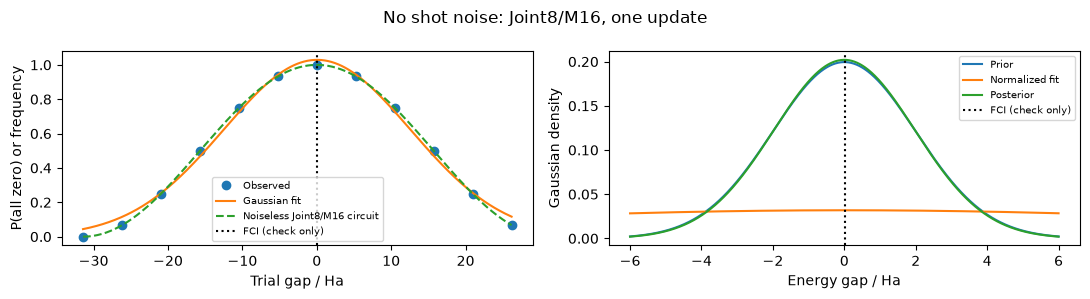

In [6]:
observed_exact = probability("both", L, TRIAL_GAPS)
fit_exact = fit_gaussian_signal(TRIAL_GAPS, observed_exact, PRIOR_MU, PRIOR_VARIANCE)
v_exact = 1 / (1 / PRIOR_VARIANCE + 1 / fit_exact["fit_variance"])
mu_exact = v_exact * (
    PRIOR_MU / PRIOR_VARIANCE + fit_exact["fit_mu"] / fit_exact["fit_variance"]
)
show_result(
    observed_exact, fit_exact, mu_exact, v_exact, "No shot noise: Joint8/M16, one update"
)
save_result("no_shot_noise", observed_exact, fit_exact, mu_exact, v_exact)
# シミュレーション確率が実際の9 qubit回路と一致することを照合。
for eps, p in zip(TRIAL_GAPS, observed_exact):
    actual = (
        abs(Statevector.from_instruction(experiment_circuit(L, float(eps))).data[0])
        ** 2
    )
    np.testing.assert_allclose(actual, p, atol=1e-10)

## 3．shot noiseありシミュレーション（ゲートノイズなし）

同じjoint回路の確率から二項乱数で全0回数を生成します。seedは42です。
06と同じGaussian参考表示を残しますが、前節の事後は引き継ぎません。


trial gap / Ha | all-zero count / shots
-31.4 | 0/1024
-26.2 | 68/1024
-20.9 | 237/1024
-15.7 | 546/1024
-10.5 | 760/1024
-5.2 | 940/1024
+0.0 | 1024/1024
+5.2 | 947/1024
+10.5 | 748/1024
+15.7 | 530/1024
+20.9 | 283/1024
+26.2 | 75/1024
fit center / Ha | posterior mean / Ha | Gaussian SD / Ha | residual RMSE
0.07653077 | 0.00184762 | 1.97571 | 0.035615
Posterior mean - FCI / Ha: -0.014057341909881902
Saved: outputs/exercise9/simulated_counts.json


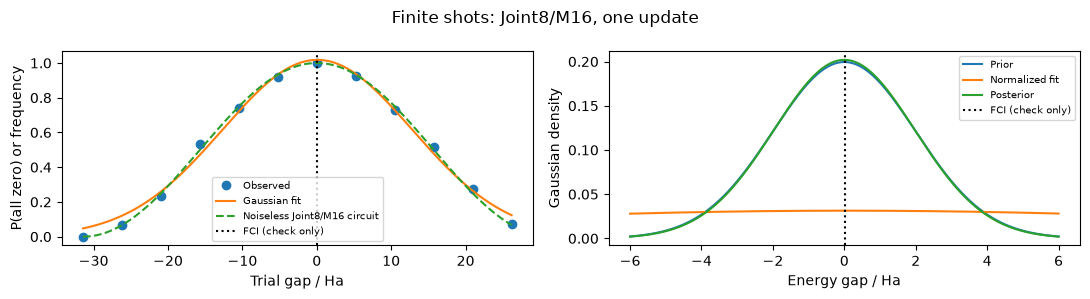

In [7]:
rng = np.random.default_rng(42)
probabilities_shots = probability("both", L, TRIAL_GAPS)
counts_shots = rng.binomial(SHOTS, probabilities_shots)
observed_shots = counts_shots / SHOTS
print("trial gap / Ha | all-zero count / shots")
for eps, count in zip(TRIAL_GAPS, counts_shots):
    print(f"{eps:+.1f} | {count}/{SHOTS}")
fit_shots = fit_gaussian_signal(TRIAL_GAPS, observed_shots, PRIOR_MU, PRIOR_VARIANCE)
v_shots = 1 / (1 / PRIOR_VARIANCE + 1 / fit_shots["fit_variance"])
mu_shots = v_shots * (
    PRIOR_MU / PRIOR_VARIANCE + fit_shots["fit_mu"] / fit_shots["fit_variance"]
)
show_result(
    observed_shots, fit_shots, mu_shots, v_shots, "Finite shots: Joint8/M16, one update"
)
save_result(
    "simulated_counts", observed_shots, fit_shots, mu_shots, v_shots, counts_shots
)

## 3a．FakeKawasakiでノイズ付きの信号を確認する

06と同じFakeKawasaki＋Aerを使います。`USE_FAKE_KAWASAKI=True` が既定です。
ゲート・読出しノイズを加え、較正配置の探索・level 3・DD・twirlingは追加しません。
08と異なり、明示的DelayへのT1/T2ノイズも追加しません。

このfakeは過去の127-qubit/ECR装置情報です。現在のCZ実機の較正とは異なります。
全countsを保存後、絶対頻度と95% Wilson区間、一定確率に対する位相依存性のp値を表示します。
p<0.05を信号検出の目安とします。単一の定常二項モデルに基づく診断であり、ギャップ精度の保証ではありません。
Trueの間は後のIBM接続・実機送信をスキップします。


In [8]:
# FakeKawasakiを初めて使う場合は、この行を有効にして実行し、カーネルを再起動してください。
# %pip install "qiskit-ibm-runtime>=0.43,<0.44" "qiskit-aer>=0.17,<0.18"
USE_FAKE_KAWASAKI = True  # True: ローカルのノイズ付き模擬Kawasakiを使う


In [9]:
def fake_kawasaki_scan(shots, seed=42):
    """Local Aer noise simulation; never connects to an IBM account or QPU."""
    if not isinstance(shots, int) or isinstance(shots, bool) or shots < 1:
        raise ValueError("shotsは正の整数を指定してください")
    try:
        import qiskit
        import qiskit_aer
        import qiskit_ibm_runtime
        from qiskit_aer import AerSimulator
        from qiskit_ibm_runtime.fake_provider import FakeKawasaki
    except ImportError as exc:
        raise ImportError(
            '先に %pip install "qiskit-ibm-runtime>=0.43,<0.44" "qiskit-aer>=0.17,<0.18" '
            "を実行してカーネルを再起動してください"
        ) from exc

    fake_backend = FakeKawasaki()
    simulator = AerSimulator.from_backend(
        fake_backend,
        method="density_matrix",
        enable_truncation=True,
        max_parallel_experiments=1,
        max_parallel_threads=4,
    )
    if (
        simulator.options.noise_model is None
        or simulator.options.noise_model.is_ideal()
    ):
        raise RuntimeError("FakeKawasakiのノイズモデルが読み込まれていません")
    logical = []
    for gap in TRIAL_GAPS:
        circuit = experiment_circuit(L, float(gap))
        circuit.measure_all()
        logical.append(circuit)
    # This uses the fake device target; execution below remains entirely local.
    isa = transpile(
        logical,
        backend=fake_backend,
        optimization_level=1,
        seed_transpiler=7,
        num_processes=1,
    )
    reports = [
        dict(
            depth=circuit.depth(),
            two_qubit_gates=sum(
                item.operation.num_qubits == 2 for item in circuit.data
            ),
            operations=dict(circuit.count_ops()),
            initial_layout=circuit.layout.initial_index_layout(filter_ancillas=True),
            final_layout=circuit.layout.final_index_layout(filter_ancillas=True),
        )
        for circuit in isa
    ]
    print(
        f"LOCAL FakeKawasaki: {len(isa)} circuits × {shots} shots; "
        f"first depth={reports[0]['depth']}, 2-qubit gates={reports[0]['two_qubit_gates']}",
        flush=True,
    )
    result = simulator.run(isa, shots=shots, seed_simulator=seed).result()
    if not result.success:
        raise RuntimeError(f"Aer simulation failed: {result.status}")
    raw = [dict(result.get_counts(i)) for i in range(len(isa))]
    if any(
        not counts
        or sum(counts.values()) <= 0
        or any(len(bits) != 9 or set(bits) - set("01") for bits in counts)
        for counts in raw
    ):
        raise ValueError("9ビットのcountsまたは実shots数が不正です")
    actual_shots = [sum(counts.values()) for counts in raw]
    zero = [counts.get("0" * 9, 0) for counts in raw]
    snapshot_hashes = {
        name: hashlib.sha256(
            (Path(fake_backend.dirname) / name).read_bytes()
        ).hexdigest()
        for name in [fake_backend.conf_filename, fake_backend.props_filename]
    }
    return dict(
        source="fake_kawasaki_noisy_counts",
        backend=fake_backend.name,
        snapshot_num_qubits=fake_backend.num_qubits,
        snapshot_last_update=fake_backend.properties().last_update_date.isoformat(),
        snapshot_sha256=snapshot_hashes,
        versions=dict(
            qiskit=qiskit.__version__,
            qiskit_ibm_runtime=qiskit_ibm_runtime.__version__,
            qiskit_aer=qiskit_aer.__version__,
        ),
        method="density_matrix",
        noise_model="AerSimulator.from_backend(FakeKawasaki())",
        noise_model_is_ideal=False,
        seed_simulator=seed,
        seed_transpiler=7,
        geometry=SELECTED_GEOMETRY,
        prep_m=SELECTED_PREP_M,
        evolution_m=SELECTED_EVOLUTION_M,
        circuit_digest=CIRCUIT_DIGEST,
        L=L,
        time=L * DT,
        trial_gaps=TRIAL_GAPS.tolist(),
        requested_shots=shots,
        actual_shots=actual_shots,
        counts_all_zero=zero,
        counts=raw,
        values=[k / n for k, n in zip(zero, actual_shots)],
        resources=reports,
    )

def plot_fake_kawasaki(record):
    plot_signal_counts(record, "LOCAL FakeKawasaki — joint preparation only", "FakeKawasaki")


LOCAL FakeKawasaki: 12 circuits × 1024 shots; first depth=665, 2-qubit gates=408
Saved: outputs/exercise9/fake_kawasaki_measurements.json
Snapshot: 2025-02-26T13:56:01-05:00 qubits: 127
trial gap / Ha | all-zero count / actual shots
-31.4 | 2/1024
-26.2 | 6/1024
-20.9 | 9/1024
-15.7 | 18/1024
-10.5 | 15/1024
-5.2 | 21/1024
+0.0 | 18/1024
+5.2 | 21/1024
+10.5 | 16/1024
+15.7 | 6/1024
+20.9 | 9/1024
+26.2 | 7/1024
Harmonic amplitude: 0.007940714547568672 phase-dependence p: 0.0002
Signal: detected (p < 0.05)


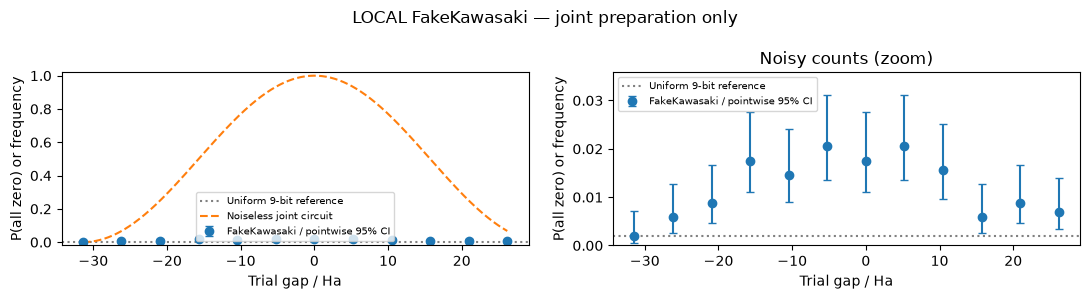

In [10]:
fake_kawasaki_record = None
if USE_FAKE_KAWASAKI:
    fake_kawasaki_record = fake_kawasaki_scan(SHOTS, seed=42)
    fake_path = Path("outputs/exercise9/fake_kawasaki_measurements.json")
    fake_path.parent.mkdir(parents=True, exist_ok=True)
    # Preserve all counts before plotting; never overwrite real IBM job records.
    fake_path.write_text(json.dumps(fake_kawasaki_record, indent=2))
    print("Saved:", fake_path)
    print(
        "Snapshot:",
        fake_kawasaki_record["snapshot_last_update"],
        "qubits:",
        fake_kawasaki_record["snapshot_num_qubits"],
    )
    print("trial gap / Ha | all-zero count / actual shots")
    for gap, k, n in zip(
        TRIAL_GAPS,
        fake_kawasaki_record["counts_all_zero"],
        fake_kawasaki_record["actual_shots"],
    ):
        print(f"{gap:+.1f} | {k}/{n}")
    fake_kawasaki_record["signal"] = summarize_device_counts(fake_kawasaki_record)
    fake_path.write_text(json.dumps(fake_kawasaki_record, indent=2))
    plot_fake_kawasaki(fake_kawasaki_record)
else:
    print("FakeKawasakiをスキップ。使う場合はUSE_FAKE_KAWASAKI=Trueにしてください。")


## IBM Quantum接続準備（実機を使う方のみ）

実機を使う場合は、先に `USE_FAKE_KAWASAKI=False` にし、次セルを `USE_IBM=True` にします。
CRN・本人のAPIキー・backendを入力してください。このセルでは送信しません。
その後のプレビューを確認し、最後に `RUN_HARDWARE=True` にしてください。


In [11]:
USE_IBM = False  # 実機を使う方のみ True に変更
IBM_SERVICE = None
IBM_INSTANCE = ""
IBM_BACKEND_NAME = ""

if USE_IBM and not globals().get("USE_FAKE_KAWASAKI", False):
    import subprocess
    import sys
    from getpass import getpass

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "qiskit==2.4.1",
            "qiskit-ibm-runtime>=0.43,<0.44",
        ]
    )
    from qiskit_ibm_runtime import QiskitRuntimeService

    IBM_INSTANCE = input("今回使うインスタンスのCRN：").strip()
    if not IBM_INSTANCE.startswith("crn:"):
        raise ValueError("インスタンスのCRN（crn:で始まる文字列）を入力してください")
    _api_key = getpass("本人のAPIキー（非表示）：").strip()
    try:
        IBM_SERVICE = QiskitRuntimeService(
            channel="ibm_quantum_platform",
            token=_api_key,
            instance=IBM_INSTANCE,
        )
    finally:
        del _api_key

    _backend_names = sorted(b.name for b in IBM_SERVICE.backends())
    print("利用可能なバックエンド：", ", ".join(_backend_names))
    if not _backend_names:
        raise RuntimeError("利用可能な実機がありません。主催者へお知らせください")
    IBM_BACKEND_NAME = input("一覧から今回使うバックエンド名を入力：").strip()
    if IBM_BACKEND_NAME not in _backend_names:
        raise ValueError(
            "一覧にあるバックエンド名を入力し、このセルを再実行してください"
        )
    print("接続確認完了：", IBM_BACKEND_NAME, "（ジョブは送信していません）")
else:
    print("IBM接続準備をスキップしました。シミュレータで演習できます。")


IBM接続準備をスキップしました。シミュレータで演習できます。


## 4．実機：joint回路の費用を確認する

06と同じlevel 1・seed=7で、現在のLの回路を実機へ配置します。ここでは送信しません。
実機で信号が検出できるかは未確認です。fakeの成功だけから判断せず、費用とcountsを確認してください。


In [12]:
backend = None
preview = None
if IBM_SERVICE is not None:
    backend = IBM_SERVICE.backend(IBM_BACKEND_NAME)
    preview = hardware_preview(backend, L=L)
    print(
        "Circuits:", len(TRIAL_GAPS), "shots per circuit:", SHOTS, "total requested shots:", len(TRIAL_GAPS) * SHOTS
    )
else:
    print("IBM接続なし：プレビューをスキップ。上のシミュレーションは実行できます。")


IBM接続なし：プレビューをスキップ。上のシミュレーションは実行できます。


### 実機の12点を測り、全0信号を確認する

06と同じMeasurementインターフェースを使い、全counts・ジョブIDを `outputs/exercise9/` に保存します。
準備回路のdigestが06と異なるため、06のcountsを再利用しません。同条件の再実行では09の保存ジョブを利用します。
平坦なデータへGaussianを強制せず、位相依存性と絶対頻度を表示します。


In [13]:
RUN_HARDWARE = False
if RUN_HARDWARE and not globals().get("USE_FAKE_KAWASAKI", False):
    if backend is None or preview is None or preview["L"] != L:
        raise RuntimeError("先にIBM接続と現在のLのプレビューを実行してください")
    ibm_meter = Measurement("ibm", SHOTS, 42, service=IBM_SERVICE, backend=backend,
        run_hardware=True, max_hardware_L=L, directory="outputs/exercise9/ibm_jobs")
    observed_ibm = ibm_meter.measure("both", L, TRIAL_GAPS, "joint_signal")
    ibm_meter.save("outputs/exercise9/ibm_measurements.json")
    raw_counts = ibm_meter.records[-1]["counts"]
    record = dict(source="ibm_joint_counts", circuit_digest=CIRCUIT_DIGEST,
        prep_m=SELECTED_PREP_M, evolution_m=SELECTED_EVOLUTION_M, L=L, time=TIME,
        trial_gaps=TRIAL_GAPS.tolist(), counts=raw_counts, values=observed_ibm.tolist())
    print("trial gap / Ha | all-zero count / actual shots")
    for gap, counts in zip(TRIAL_GAPS, raw_counts):
        print(f"{gap:+.3f} | {counts.get('0'*9, 0)}/{sum(counts.values())}")
    record["signal"] = summarize_device_counts(record)
    path = Path("outputs/exercise9/ibm_signal.json")
    path.write_text(json.dumps(record, indent=2))
    plot_signal_counts(record, "IBM hardware — joint preparation only", "IBM hardware")
    print("Saved:", path)
elif globals().get("USE_FAKE_KAWASAKI", False):
    print("FakeKawasakiモード：実機送信をスキップしました。")
else:
    print("実機送信なし。接続・プレビュー後にRUN_HARDWARE=Trueにしてください。")


FakeKawasakiモード：実機送信をスキップしました。


## 5．読み方

- joint準備のfidelityは標的との理想状態の近さです。ノイズ下で同じfidelityが残るという意味ではありません。
- p値は一定確率に対する位相依存性の診断です。小さいp値だけでギャップを推定できたとは判断しません。
- 既定はL=1です。L=4を試すときは設定セル以降を再実行します。ノイズやshots不足で信号が消える可能性があります。
- fakeは06と同じノイズ方式です。08のjoint armと異なり、明示的なidle緩和を追加していません。
- 09はjoint準備だけの簡潔な実験です。較正配置・twirling・DD等の比較には08を使ってください。
